# ASMSA v2 &mdash; PLUMED export

&#8592; [Train](04-train.ipynb) &nbsp;|&nbsp; [Metadynamics](06-md.ipynb) &#8594;

| | |
|---|---|
| **What it does** | Turn the trained encoder into a TorchScript collective variable PLUMED can evaluate, and write the metadynamics input. |
| **Typical runtime** | under a minute |
| **Needs** | a checkpoint from <a href='04-train.ipynb'>04-train</a>, plus a GROMACS topology <code>.gro</code> |
| **Produces** | <code>cv-*-plumed.pt</code>, <code>cv-*-batch.pt</code>, <code>plumed.dat</code> |

---

This is the stage where mistakes are most expensive, because they do not announce
themselves: a wrongly exported CV runs perfectly happily and biases a meaningless
coordinate for as long as you let the simulation run. So every step here is verified
numerically before anything is written.

Two things have to be right:

1. **The whole transform chain must be inside the exported model.** PLUMED supplies
   atom positions, so featurization *and standardization* have to travel with it. The
   standard `PYTORCH_MODEL` action receives scalar inputs; POSITION x/y/z components
   supply the coordinates in the model's expected order.
2. **The atom numbering must be translated.** ASMSA trains on atoms numbered as in the
   PDB; the simulation runs on a `pdb2gmx` topology with hydrogens added and atoms
   reordered within residues. Each POSITION action follows featurizer order while its
   `ATOM=` index refers to the topology.

In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt
import mdtraj as md

import asmsa_v2 as asmsa
from asmsa_v2.export import (
    cv_grid, export_cv_models, map_pdb_to_topology,
    write_plumed_dat, write_plumed_driver_dat,
)
from asmsa_v2.viz import use_asmsa_style

use_asmsa_style()
project = asmsa.Project.load('run')

bundle = torch.load(project.features_file, weights_only=False)
Xs = bundle['features']
n_atoms = int(bundle['n_atoms'])
scaler = asmsa.FeatureScaler.load(project.scaler_file)
print(f'{n_atoms} atoms, {Xs.shape[1]} features, latent_dim={project.latent_dim}')

144 atoms, 596 features, latent_dim=2


## 1. Rebuild the trained model

The architecture is read back from the checkpoint rather than re-specified, so it cannot
drift out of step with the saved weights.

In [2]:
payload = torch.load(project.checkpoint_file, map_location='cpu', weights_only=False)
mc = asmsa.ModelConfig.from_dict(payload['model_config'])

model = asmsa.AAE(
    feature_dims=payload['feature_dims'],
    latent_dim=mc.latent_dim,
    encoder_widths=mc.encoder_widths,
    decoder_widths=mc.decoder_widths,
    disc_widths=mc.disc_widths,
    activation=mc.activation,
    batchnorm=mc.batchnorm,
    spectral_norm_disc=mc.spectral_norm_disc,
)
model.load_state_dict(payload['model_state'])
model.eval()

if 'quality' in payload:
    print('quality recorded at training time:')
    for k, v in payload['quality'].items():
        print(f'  {k:<16} {v:.4f}')

quality recorded at training time:
  recon_relative   0.8882
  kl_prior         0.2043
  vamp2            nan
  effective_dim    1.9997


## 2. Rebuild the featurizer

It must be **the same** featurizer that produced the training features. Rebuilding it
from the project config and then checking it against the saved feature tensor is what
guarantees that.

In [3]:
traj = md.load(str(project.traj_path), top=str(project.conf_path))
components = {k: traj.top.select(v) for k, v in (project.components or {}).items()}

if components and len(components) >= 2:
    molecule = asmsa.auto_features(
        traj, components=components,
        inter_strategy=project.inter_strategy,
        extract_dihedrals=project.use_dihedrals,
        pdb_for_dihedrals=str(project.conf_path) if project.use_dihedrals else None,
    )
else:
    diheds = (asmsa.extract_dihedral_indices_local(str(project.conf_path))
              if project.use_dihedrals else None)
    molecule = asmsa.Molecule(
        pdb=str(project.conf_path), n_atoms=n_atoms, diheds=diheds,
        fms=[asmsa.NBDistancesSparse(n_atoms, density=project.nb_density)],
    )

mol_model = molecule.get_model()
X_check = asmsa.featurize_frames(traj.xyz[:200], mol_model)
raw = bundle['features_raw'][:200]
err = float((X_check - raw).abs().max())
print(f'rebuilt featurizer vs saved features: max |diff| = {err:.3e}')
assert err < 1e-4, (
    'the rebuilt featurizer does not match the one used for training; '
    'the project config must have changed since 02-prepare')
print('OK')

rebuilt featurizer vs saved features: max |diff| = 5.007e-06
OK


## 3. Export the collective variable

Two traced models are produced from the same chain
(`positions -> internal coordinates -> standardize -> encoder -> z`):

| Artifact | Signature | Used by |
|---|---|---|
| `cv-*-plumed.pt` | `[n_atoms*3] -> [latent_dim]` | PLUMED, once per MD step |
| `cv-*-batch.pt` | `[n_frames, n_atoms, 3] -> [n_frames, latent_dim]` | analysing trajectories in Python |
| `cv-*-encoder.pt` | `[n, n_features] -> [n, latent_dim]` | encoding pre-featurized data |
| `cv-*-decoder.pt` | `[n, latent_dim] -> [n, n_features]` | decoding latent points back to internal coordinates |

Both are traced in **eval** mode on **CPU**. Neither is cosmetic: the encoder contains
BatchNorm, and a model traced in training mode would use batch statistics &mdash; for
PLUMED's batch of one that is degenerate and the CV would be garbage. CPU because PLUMED
loads the file inside the GROMACS process on the host.

The export then verifies, and **raises** rather than writing a broken model, that the
traced batch model matches the eager model, and that the PLUMED model agrees with the
batch model frame by frame.

In [4]:
paths = export_cv_models(
    model, mol_model, scaler,
    n_atoms=n_atoms,
    out_dir=project.dir('models'),
    mol_id='complex' if (components and len(components) >= 2) else 'complex',
    name=project.cv_stem,
    example_xyz=traj.xyz[:8],
    check_tolerance=1e-4,
)
for k, p in paths.items():
    print(f'  {k:<9} {p.name}')
print()
print(paths['check'].read_text())

/home/tedeschg/prj/ASMSA_v2/src/asmsa_v2/featurize/mol_model.py:324: TracerWarning: Converting a tensor to a Python boolean might cause the trace to be incorrect. We can't record the data flow of Python values, so this value will be treated as a constant in the future. This means that the trace might not generalize to other inputs!
  assert input.shape[0] == self.n_atoms
/home/tedeschg/prj/ASMSA_v2/src/asmsa_v2/featurize/mol_model.py:325: TracerWarning: Converting a tensor to a Python boolean might cause the trace to be incorrect. We can't record the data flow of Python values, so this value will be treated as a constant in the future. This means that the trace might not generalize to other inputs!
  assert input.shape[1] == 3


  batch     cv-norm-batch.pt
  plumed    cv-norm-plumed.pt
  encoder   cv-norm-encoder.pt
  decoder   cv-norm-decoder.pt
  check     cv-norm-export-check.txt

traced batch vs eager      : max |diff| = 1.192e-07
plumed (per frame) vs batch: max |diff| = 1.788e-07
output shape (batch)       : (8, 2)
output shape (plumed)      : (1, 2) per frame
finite outputs             : True


/home/tedeschg/prj/ASMSA_v2/src/asmsa_v2/featurize/mol_model.py:324: TracerWarning: Converting a tensor to a Python boolean might cause the trace to be incorrect. We can't record the data flow of Python values, so this value will be treated as a constant in the future. This means that the trace might not generalize to other inputs!
  assert input.shape[0] == self.n_atoms
/home/tedeschg/prj/ASMSA_v2/src/asmsa_v2/featurize/mol_model.py:325: TracerWarning: Converting a tensor to a Python boolean might cause the trace to be incorrect. We can't record the data flow of Python values, so this value will be treated as a constant in the future. This means that the trace might not generalize to other inputs!
  assert input.shape[1] == 3
/home/tedeschg/prj/ASMSA_v2/.venv/lib/python3.12/site-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


### Independent check on the full trajectory

The export's internal check uses 8 frames. This runs the saved TorchScript model over
the *entire* trajectory, straight from coordinates, and compares with the latent the
training notebook computed from pre-featurized, pre-standardized data. Agreement means
the featurizer, the scaler and the encoder are all correctly chained inside the
artifact.

**What to look for:** a max difference around 1e-6 or smaller, and two scatter plots
that are indistinguishable.

TorchScript-from-coordinates vs training latent: max |diff| = 5.603e-06


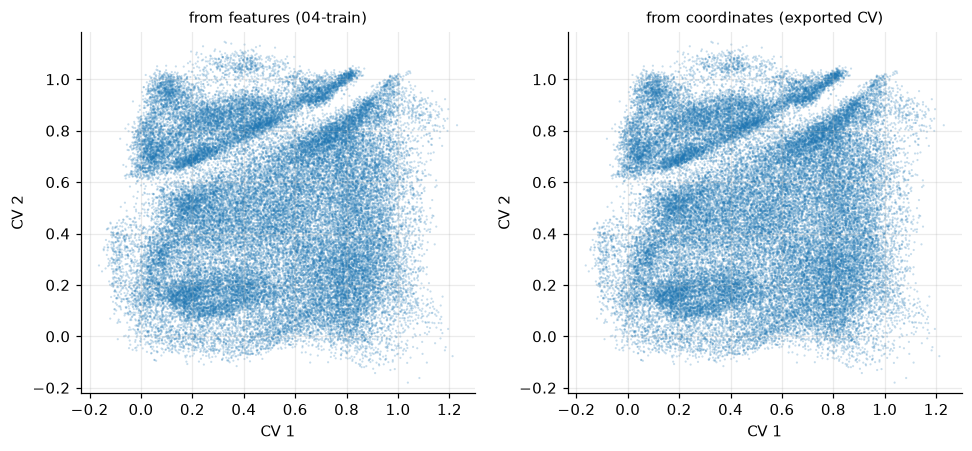

In [5]:
batch_cv = torch.jit.load(str(paths['batch']))
batch_cv.eval()
with torch.no_grad():
    z_from_coords = batch_cv(torch.as_tensor(traj.xyz, dtype=torch.float32)).numpy()

latent_file = project.dir('models') / f'latent-{project.model_name}.npy'
if latent_file.exists():
    z_training = np.load(latent_file)
    err = np.abs(z_from_coords - z_training).max()
    print(f'TorchScript-from-coordinates vs training latent: max |diff| = {err:.3e}')
    assert err < 1e-3, 'the exported CV does not reproduce the trained latent'

    fig, axes = plt.subplots(1, 2, figsize=(9, 4.2))
    for ax, (z, title) in zip(axes, [(z_training, 'from features (04-train)'),
                                     (z_from_coords, 'from coordinates (exported CV)')]):
        ax.scatter(z[:, 0], z[:, 1], s=2, alpha=0.25)
        ax.set_title(title, fontsize=10)
        asmsa.viz.latent_axes(ax)
    plt.tight_layout(); plt.show()
else:
    z_training = z_from_coords
    print('no saved training latent to compare against; using the exported one')

### Verify the per-step PLUMED signature

PLUMED calls the model with a flat vector of the positions of the atoms listed in
`ATOMS=`. Confirm the shapes and that a single frame gives the same CV as the batch.

In [6]:
plumed_cv = torch.jit.load(str(paths['plumed']))
plumed_cv.eval()

flat = torch.as_tensor(traj.xyz[0].reshape(-1), dtype=torch.float32)
with torch.no_grad():
    one = plumed_cv(flat)
print(f'input  {tuple(flat.shape)}  (= n_atoms * 3 = {n_atoms} * 3)')
print(f'output {tuple(one.shape)}  (= latent_dim)')
print(f'agrees with the batch model: '
      f'{np.abs(one.numpy() - z_from_coords[0]).max():.3e}')

input  (432,)  (= n_atoms * 3 = 144 * 3)
output (1, 2)  (= latent_dim)
agrees with the batch model: 8.941e-08


## 4. Translate the atom numbering

`pdb2gmx` adds hydrogens and reorders atoms within each residue &mdash; notably it moves
the backbone carboxyl to the end. v1's notebook documents the consequence for
trp-cage's first residue: the eight PDB atoms of ASP must be written as
`ATOMS=1,5,13,14,7,10,11,12`.

v1 derived this from the sort order of a GROMACS index file and told the user to "check
the results manually". Here the mapping is resolved by matching
`(chain, residue number, residue name, atom name)` between the two files, with aliases
for force-field renamings (`HIS`&rarr;`HISE`, `O`/`OXT`&rarr;`OC1`/`OC2`, ...). It is
deterministic, it names any atom it cannot match, and it **refuses** to produce a
mapping it cannot justify.

In [7]:
# The topology describing the simulated system, including hydrogens.
# Normally the .gro produced by pdb2gmx in 02-prepare.
topology = project.root / project.gro
if not topology.exists():
    fallback = project.root / 'inputs' / 'topology.gro'   # demo system's mock
    if fallback.exists():
        topology = fallback
        print(f'using the demo mock topology: {topology.relative_to(project.root)}')
    else:
        raise FileNotFoundError(
            f'no topology at {topology}. Run pdb2gmx in 02-prepare.ipynb '
            f'(it needs GROMACS installed).')

atom_map = map_pdb_to_topology(project.conf_path, topology, strict=True)
atom_map

featurized atoms,144
topology atoms,272
first indices,"1,5,7,10,11,12,13,14,15,17,19,23..."


**What to look for:** `resolved`, and an **identity mapping of `False`** &mdash;
`False` is the expected answer, because `pdb2gmx` really does reorder atoms. A `True`
here would be the suspicious case, meaning either the topology has no hydrogens or you
pointed at the wrong file.

Spot-check the first residue by hand against your own files; it costs a minute and
catches the one error class that otherwise ruins a multi-day simulation.

In [8]:
# Print the mapping for the first few atoms, with names, so it can be eyeballed.
conf_top = md.load(str(project.conf_path)).topology
topo_top = md.load(str(topology)).topology
conf_atoms = list(conf_top.atoms)
topo_atoms = list(topo_top.atoms)

print(f'{"pdb #":>6} {"pdb atom":<18} -> {"topol #":>8} {"topol atom":<18}')
for i, j in list(enumerate(atom_map.atoms_1based))[:12]:
    a = conf_atoms[i]
    b = topo_atoms[int(j) - 1]
    print(f'{i + 1:>6} {a.residue.name}{a.residue.resSeq}:{a.name:<12} '
          f'-> {int(j):>8} {b.residue.name}{b.residue.resSeq}:{b.name:<12}')

 pdb # pdb atom           ->  topol # topol atom        
     1 ASP1:N            ->        1 ASP1:N           
     2 ASP1:CA           ->        5 ASP1:CA          
     3 ASP1:CB           ->        7 ASP1:CB          
     4 ASP1:CG           ->       10 ASP1:CG          
     5 ASP1:OD1          ->       11 ASP1:OD1         
     6 ASP1:OD2          ->       12 ASP1:OD2         
     7 ASP1:C            ->       13 ASP1:C           
     8 ASP1:O            ->       14 ASP1:O           
     9 ALA2:N            ->       15 ALA2:N           
    10 ALA2:CA           ->       17 ALA2:CA          
    11 ALA2:CB           ->       19 ALA2:CB          
    12 ALA2:C            ->       23 ALA2:C           


## 5. Grid and hill width

PLUMED pre-allocates a grid for the accumulated bias, so its extent must be fixed in
advance. Metadynamics *deliberately* pushes the system outside the region your unbiased
trajectory sampled, so the grid is padded generously: too narrow and the simulation
escapes it and crashes; too wide only costs some memory. `margin=3.0` and
`sigma = range/20` are v1's values.

The CV range is taken from the **test** split, so it reflects frames the model never
trained on.

In [9]:
sp = np.load(project.split_file, allow_pickle=False)
z_ref = z_from_coords[sp['test']] if sp['test'].size > 50 else z_from_coords

grid = cv_grid(z_ref, margin=3.0, sigma_divisor=20.0)
print(grid.report())

CVGrid (margin=3.0x range, sigma=range/20)
  CV0: observed [-0.152, +1.173]  grid [-4.126, +5.148]  sigma 0.0662
  CV1: observed [-0.120, +1.142]  grid [-3.906, +4.929]  sigma 0.0631


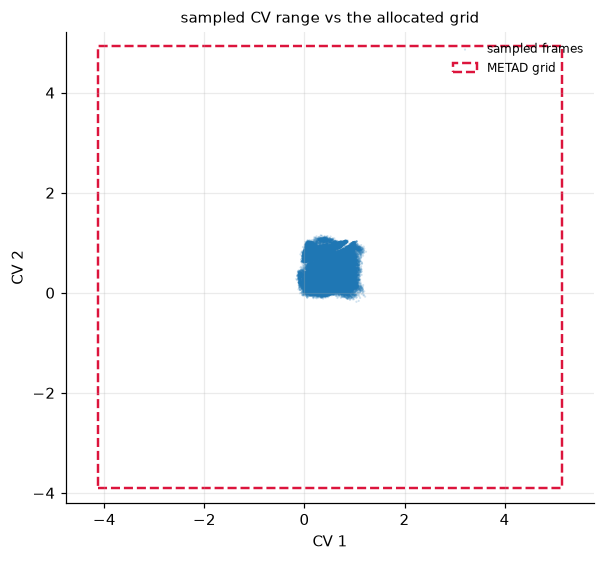

In [10]:
fig, ax = plt.subplots(figsize=(5.6, 5.2))
ax.scatter(z_from_coords[:, 0], z_from_coords[:, 1], s=2, alpha=0.2,
           label='sampled frames')
from matplotlib.patches import Rectangle
ax.add_patch(Rectangle((grid.grid_min[0], grid.grid_min[1]),
                       grid.grid_max[0] - grid.grid_min[0],
                       grid.grid_max[1] - grid.grid_min[1],
                       fill=False, ec='crimson', lw=1.6, ls='--',
                       label='METAD grid'))
ax.legend(fontsize=8)
ax.set_title('sampled CV range vs the allocated grid')
asmsa.viz.latent_axes(ax)
plt.tight_layout(); plt.show()

## 6. Write `plumed.dat`

Well-tempered metadynamics on the two latent coordinates.

| Setting | Note |
|---|---|
| `BIASFACTOR` | Well-tempered bias factor. 10&ndash;20 is typical; `1` would be plain metadynamics, which does not converge. |
| `PACE` | Steps between hill depositions. 500&ndash;1000 is usual. |
| `HEIGHT` | Initial hill height in kJ/mol. |
| `TEMP` | Written explicitly so the bias factor is interpreted against a stated temperature rather than whatever the MD engine reports. |
| `CALC_RCT` | Accumulates the time-dependent offset `c(t)` needed to reweight the biased trajectory back to unbiased free energies. Cheap, and **you cannot add it retroactively** &mdash; leave it on. |
| `RESTART` | Resume from an existing `HILLS`. [06-md](06-md.ipynb) creates the empty file before the first run. |

In [11]:
import shutil

md_dir = project.dir('md')
model_filename = paths['plumed'].name

# PLUMED resolves FILE= relative to the simulation's working directory,
# so the model is copied next to where mdrun will run.
for key in ('plumed', 'batch'):
    shutil.copy2(paths[key], md_dir / paths[key].name)

plumed_dat = write_plumed_dat(
    project.plumed_dat,
    model_file=model_filename,
    atom_map=atom_map,
    grid=grid,
    n_cv=project.latent_dim,
    temperature=project.temperature,
    pace=1000,
    height=1.0,
    biasfactor=15.0,
    stride_print=100,
    calc_rct=True,
    restart=True,
)

# A bias-free variant, for recomputing CVs on any trajectory with `plumed driver`.
write_plumed_driver_dat(md_dir / 'plumed-driver.dat', model_filename, atom_map,
                        n_cv=project.latent_dim)

print(plumed_dat.read_text())

# Generated by asmsa_v2.export.plumed.write_plumed_dat
# CVs are the latent coordinates of the trained ASMSA autoencoder.
# POSITION actions follow featurizer (PDB) order and use topology indices.
# See asmsa_v2.export.plumed.map_pdb_to_topology.

# Resume from an existing HILLS file (create it with `touch HILLS`
# before the first run).
RESTART

# Reassemble molecules broken by periodic boundary conditions
# before the CV is evaluated.
WHOLEMOLECULES ENTITY0=1-272

model_position_0: POSITION ATOM=1
model_position_1: POSITION ATOM=5
model_position_2: POSITION ATOM=7
model_position_3: POSITION ATOM=10
model_position_4: POSITION ATOM=11
model_position_5: POSITION ATOM=12
model_position_6: POSITION ATOM=13
model_position_7: POSITION ATOM=14
model_position_8: POSITION ATOM=15
model_position_9: POSITION ATOM=17
model_position_10: POSITION ATOM=19
model_position_11: POSITION ATOM=23
model_position_12: POSITION ATOM=24
model_position_13: POSITION ATOM=25
model_position_14: POSITION ATOM=27
mo

## 7. Before you start a long simulation

Each of these failed silently at least once in the history of this pipeline.

- [ ] The atom map reported **resolved**, and you eyeballed the first residue above.
- [ ] The generated POSITION actions cover every featurized atom in the expected order.
- [ ] The exported CV reproduced the training latent to ~1e-6.
- [ ] `latent_dim` CVs appear in `ARG=` as `model.node-0 ... model.node-(n-1)`.
- [ ] `cv-*-plumed.pt` sits in the directory `mdrun` will run in.
- [ ] `SIGMA` is roughly 1/20 of the CV range &mdash; much larger smears out features,
      much smaller converges very slowly.
- [ ] Your PLUMED build has the PyTorch module with the standard `PYTORCH_MODEL` action.
      [06-md](06-md.ipynb) checks this.

In [12]:
n_expected = n_atoms
n_positioned = len(atom_map.atoms_1based)
print(f'POSITION entries: {n_positioned}   featurizer expects: {n_expected}   '
      f'{"OK" if n_positioned == n_expected else "MISMATCH"}')
assert n_positioned == n_expected

for f in sorted(md_dir.iterdir()):
    print(f'  {f.name}')

POSITION entries: 144   featurizer expects: 144   OK
  cv-norm-batch.pt
  cv-norm-plumed.pt
  plumed-driver.dat
  plumed.dat


---

&#8592; [Train](04-train.ipynb) &nbsp;|&nbsp; **Next: [Metadynamics](06-md.ipynb)** &#8594;